## Feature Importance in a Random Forest:

A trained random forest can tell us **which input features it relied on most**. `feature_importances_` returns one number per feature: how much, on average, splits on that feature reduced impurity across all the trees. The values are normalised to sum to 1, and a higher value means the feature helped more in separating the classes.

Here the data is images, so each feature is a **pixel**. That lets us draw the importances as a heatmap and see *which parts of the image* the forest looks at.

In [1]:
import pandas as pd
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier

## Data:

`MNIST.csv` holds handwritten digits. Each row is one 28 × 28 grayscale image flattened into 784 pixel columns (`pixel0` to `pixel783`, values 0 to 255), and `label` is the digit it shows.

`X` is all the pixel columns and `y` is the label.

In [2]:
df = pd.read_csv('D:/Important Files/Machine Learning/Datasets/MNIST.csv')
df.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [3]:
X = df.iloc[:,1:]
y = df.iloc[:,0]


### Looking at one image:

Reshaping a row of 784 values back into a 28 × 28 grid and drawing it as a heatmap shows the digit. This one is a 0.

<Axes: >

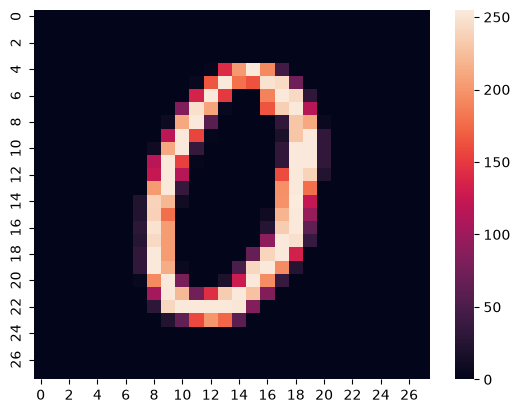

In [4]:
sns.heatmap(X.iloc[5].values.reshape(28,28))

In [5]:
rf = RandomForestClassifier()
rf.fit(X, y)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

## Feature importances:

`feature_importances_` has one value per pixel, so its shape is `(784,)`, and the values sum to 1. Many of them are exactly 0, including all the ones at the start of the array. Those pixels sit in the top-left corner, which is probably blank in every image, so no tree ever splits on them.

In [6]:
rf.feature_importances_

array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 9.81642735e-07, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 3.97570253e-06,
       7.71199417e-07, 1.55534610e-06, 2.40606281e-06, 1.51212754e-06,
       1.63443685e-06, 1.02745827e-06, 1.39896380e-06, 5.79454570e-06,
       3.02890446e-06, 2.24518241e-06, 1.44272502e-06, 5.06077823e-07,
       4.70459974e-07, 4.81183258e-07, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
      

In [7]:
rf.feature_importances_.shape

(784,)

### Importance heatmap:

Reshaping the 784 importances into a 28 × 28 grid gives an importance map of the image. Bright pixels are the ones the forest relied on most, and dark pixels carry little or no information.

In the plot, the important pixels cluster in the **centre**, where the digit strokes are, while the borders are close to 0. The highest value is only about 0.01, so no single pixel dominates. The forest spreads its attention over many pixels.

**A caveat:** impurity-based importances describe what *this trained model* used, not what is causally important, and neighbouring pixels are strongly correlated, so they share the credit between them. For a more reliable ranking, `sklearn.inspection.permutation_importance` on held-out data is a good cross-check.

<Axes: >

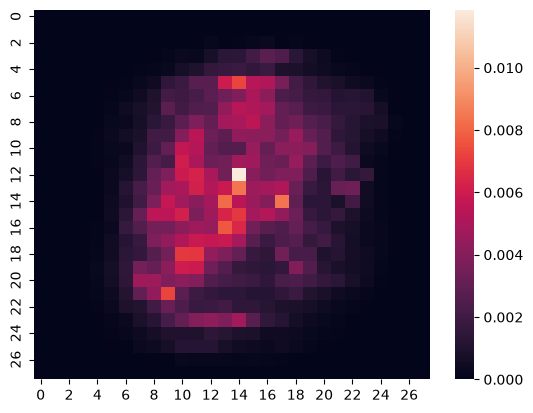

In [8]:
sns.heatmap(rf.feature_importances_.reshape(28,28))